# Classical overview

macro-F1 against window length per classifier, from `csi_bench.results_api` (run `csi-bench report` first).

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt

from csi_bench.results_api import load_index

room = "mixed"  # r1, r2 or mixed
include_dirty = False  # True to include runs made with uncommitted changes
# Jupyter starts in notebooks/, so look for runs/ here and in the parent folders
runs = next(p / "runs" for p in [Path.cwd(), *Path.cwd().parents] if (p / "runs").is_dir())
index = load_index(runs)  # run `csi-bench report` first; reads runs/index.parquet
done = index[
    (index.status == "done")
    & (index.role == "comparison")
    & (include_dirty | ~index.dirty)
    & (index.room_setting == room)
].copy()
# one split hash only: scores on different splits are not comparable
done = done[done.split_hash == done.split_hash.iloc[0]] if len(done) else done
print(f"{len(done)} finished comparison runs for room setting {room!r}")
if done.empty:
    print("nothing to plot: run `csi-bench report` (add --include-dirty if the tree is dirty) or change `room`")

0 finished comparison runs for room setting 'mixed'
nothing to plot: run `csi-bench report` (add --include-dirty if the tree is dirty) or change `room`


In [5]:
done

,run_id,status,role,dataset,split_hash,dirty,method,room_setting,window_len,stride,variant,n_seeds,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,val_accuracy_std,test_macro_f1_mean,test_macro_f1_std,test_accuracy_mean,test_accuracy_std


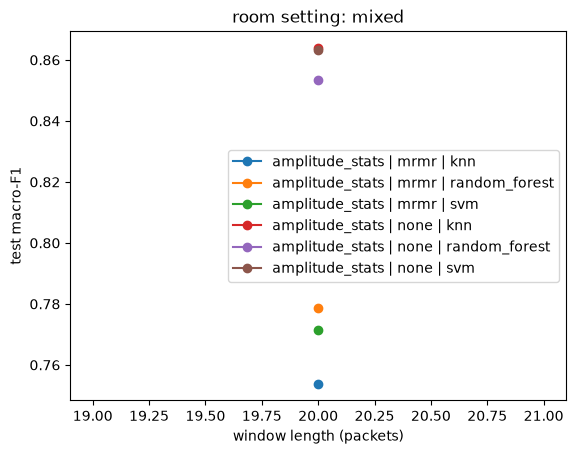

In [3]:
if not done.empty:
    # per method and window length, the run with the best validation macro-F1
    best = done.loc[done.groupby(["method", "window_len"]).val_macro_f1_mean.idxmax()]
    for method, group in best.groupby("method"):
        plt.plot(group.window_len, group.test_macro_f1_mean, marker="o", label=method)
    plt.xlabel("window length (packets)")
    plt.ylabel("test macro-F1")
    plt.title(f"room setting: {room}")
    plt.legend()
    plt.show()